# Discovering the wind-turbine drivetrain — and why closed-loop data may not identify it

The wind thread of this module so far discovered *laws* (the wake decay, the erosion slope). This notebook discovers
the turbine's *dynamics*: the single-mass drivetrain of `pyutils.benchmarks.turbine`,
$$J\,\dot\omega=T_{\mathrm{aero}}(\omega,v)-T_{\mathrm{gen}},\qquad
T_{\mathrm{aero}}=\tfrac12\rho A\,C_p(\lambda)\,\frac{v^3}{\omega},\qquad \lambda=\frac{\omega R}{v},$$
in region II (below rated wind, pitch $\beta=0$), from logs of rotor speed $\omega$, wind speed $v$ and generator
torque $T_{\mathrm{gen}}$. The unknowns are the inertia $J$ and the power-coefficient map $C_p(\lambda)$.

1. **A library from dimensional analysis.** $T_{\mathrm{aero}}=q\,C_p(\lambda)/\lambda$ with $q=\tfrac12\rho AR\,v^2$, so
   expanding $C_p$ in powers of $\lambda$ gives the SINDYc library $\{q\lambda^{k-1}\}_{k=0}^{4}\cup\{T_{\mathrm{gen}}\}$.
   The wind speed enters every column as a parameter: this is **parametric SINDy**.
2. **Closed-loop data under the standard controller do not identify $J$.** The maximum-power-tracking law
   $T_{\mathrm{gen}}=K\omega^2$ is *exactly* a multiple of the library column $q\lambda^{2}$, as derived below.
3. **Excitation fixes it.** Dither the torque gain and $J$ and $C_p$ come out right.
4. **The test that tells them apart** is a different controller: both models reproduce the controller they were
   identified under; only one survives a change of gain.
5. **Noise**, finite differences against the weak form.

The prose narrates the **default** run. Change the values below and *Run All*; checks that quote the default numbers are skipped when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
V_MEAN, TI, TAU_W, SEED = 7.5, 0.12, 20.0, 1     # identification wind: OU turbulence of turbine.turbulent_wind
T_END, DT = 600.0, 0.05                          # log length and sampling step [s]
DITHER = [(0.5, 0.05, 0.0), (0.3, 0.13, 1.0), (0.2, 0.31, 2.0)]   # torque-gain dither: (amplitude, rad/s, phase)
DEG = 4                                          # C_p(lambda) polynomial degree
V_TEST, SEED_TEST = 8.5, 2                       # unseen validation wind
GAINS = [1.0, 1.4, 0.6]                          # controller gains of the validation runs (1.0 = the MPPT law)
NOISES = [0.0, 0.001, 0.005, 0.01]               # noise on omega, fraction of its std
# --------------------------------------------------------------------------
DEFAULTS = dict(V_MEAN=7.5, TI=0.12, TAU_W=20.0, SEED=1, T_END=600.0, DT=0.05,
                DITHER=[(0.5, 0.05, 0.0), (0.3, 0.13, 1.0), (0.2, 0.31, 2.0)], DEG=4, V_TEST=8.5, SEED_TEST=2,
                GAINS=[1.0, 1.4, 0.6], NOISES=[0.0, 0.001, 0.005, 0.01])
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

### Setup: the turbine and the logs

Everything physical is imported from `turbine.TurbineParams` (NREL 5-MW-like: $R=63$~m, $J=38.6\times10^6$~kg\,m$^2$,
the Heier $C_p(\lambda,\beta)$ map). The integration is the benchmark's explicit step with pitch held at zero (region
II), written out here so that the generator torque law can be changed: $T_{\mathrm{gen}}=g(t)\,K\omega^2$ with
$g\equiv1$ the maximum-power-tracking (MPPT) law of the benchmark controller, or a dithered gain
$g(t)=1+\sum_i a_i\sin(\Omega_it+\phi_i)$. Because the step is explicit Euler, the forward difference of $\omega$ is
the exact model derivative; the noise experiment at the end uses measured-style derivatives instead.

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted; set_plot_style()
from pyutils.benchmarks import turbine
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

p = turbine.TurbineParams(); R, A, rho, J, K = p.R, p.A, p.rho, p.J, p.K
print(f'lambda_opt = {p.lam_opt:.2f}, Cp_max = {p.Cp_max:.3f}, v_rated = {p.v_rated:.1f} m/s, J = {J/1e6:.1f}e6 kg m^2, '
      f'K = {K:.3e} N m s^2')

def dither(t): return sum(a*np.sin(w*t + ph) for a, w, ph in DITHER)
def simulate(v_fn, t_end, gain=lambda t: 1.0, rhs=None):
    # explicit-Euler drivetrain, region II (beta = 0); T_gen = gain(t) K omega^2, capped at T_rated
    n = int(round(t_end/DT)); t = np.linspace(0, n*DT, n + 1); om = p.lam_opt*v_fn(0.0)/R
    OM, V, TG, DOM = (np.empty(n + 1) for _ in range(4))
    for k in range(n + 1):
        v = v_fn(t[k]); tg = min(gain(t[k])*K*om**2, p.T_rated)
        d = (0.5*rho*A*float(p.Cp(om*R/v, 0.0))*v**3/om - tg)/J if rhs is None else rhs(om, v, tg)
        OM[k], V[k], TG[k], DOM[k] = om, v, tg, d
        if k < n: om = om + DT*d
    return t, OM, V, TG, DOM

v_id, _, _ = turbine.turbulent_wind(V_MEAN, t_end=T_END, dt=DT, TI=TI, tau=TAU_W, seed=SEED)
logs = {'MPPT': simulate(v_id, T_END), 'excited': simulate(v_id, T_END, gain=lambda t: 1 + dither(t))}
for lab, (t, OM, V, TG, DOM) in logs.items():
    lam = OM*R/V
    print(f'{lab:8s}: v in [{V.min():.1f}, {V.max():.1f}] m/s, omega in [{OM.min():.3f}, {OM.max():.3f}] rad/s, '
          f'lambda in [{lam.min():.2f}, {lam.max():.2f}]')

lambda_opt = 8.10, Cp_max = 0.480, v_rated = 11.1 m/s, J = 38.6e6 kg m^2, K = 1.724e+06 N m s^2
MPPT    : v in [5.0, 9.4] m/s, omega in [0.743, 1.114] rad/s, lambda in [6.69, 10.41]
excited : v in [5.0, 9.4] m/s, omega in [0.645, 1.273] rad/s, lambda in [5.67, 12.75]


## 1–2. The library, and why MPPT data cannot identify $J$

Divide the drivetrain equation by $J$ and expand $C_p(\lambda)=\sum_{k=0}^{D}c_k\lambda^k$:
$$\dot\omega=\sum_{k=0}^{D}\frac{c_k}{J}\,q\,\lambda^{k-1}\;-\;\frac1J\,T_{\mathrm{gen}},\qquad q=\tfrac12\rho AR\,v^2 .$$
That is a linear regression on the columns $\theta_k=q\lambda^{k-1}$ and $T_{\mathrm{gen}}$, with $J=-1/\xi_{T}$ and
$c_k=-\xi_k/\xi_T$. Now insert the MPPT law. Since $\omega=\lambda v/R$,
$$T_{\mathrm{gen}}=K\omega^2=K\frac{\lambda^2v^2}{R^2}=\frac{2K}{\rho AR^3}\;q\,\lambda^{2}\;=\;\frac{2K}{\rho AR^3}\,\theta_3 :$$
the generator torque is an **exact** multiple of a library column, for every sample, whatever the wind. The design
matrix is rank-deficient, and $J$ and $c_3$ can trade off along the null direction without changing the fit. The
controller that makes the turbine efficient is the one that hides its inertia.

In [3]:
NAMES = [f'q lam^{k-1}' for k in range(DEG + 1)] + ['T_gen']
def design(OM, V, TG):
    lam = OM*R/V; q = 0.5*rho*A*R*V**2
    return np.stack([q*lam**(k - 1) for k in range(DEG + 1)] + [TG], 1)
fits = {}
for lab, (t, OM, V, TG, DOM) in logs.items():
    Th = design(OM, V, TG); Tn = Th/np.linalg.norm(Th, axis=0)
    xi = np.linalg.lstsq(Th, DOM, rcond=None)[0]; fits[lab] = xi
    ratio = TG/Th[:, 3]
    print(f'{lab:8s}: cond(normalized library) = {np.linalg.cond(Tn):.1e};  T_gen / (q lam^2) ranges over '
          f'[{ratio.min():.4e}, {ratio.max():.4e}] (2K/(rho A R^3) = {2*K/(rho*A*R**3):.4e});  '
          f'J = {-1/xi[-1]:.6g} kg m^2 (true {J:.6g})')
lg = np.linspace(3, 13, 101)
def cp_hat(xi, l): return sum(-xi[k]/xi[-1]*l**k for k in range(DEG + 1))
lam_x = logs['excited'][1]*R/logs['excited'][2]; inside = (lg >= lam_x.min()) & (lg <= lam_x.max())
cp_err_in = float(np.abs(cp_hat(fits['excited'], lg) - p.Cp(lg, 0.0))[inside].max())
cp_err_out = float(np.abs(cp_hat(fits['excited'], lg) - p.Cp(lg, 0.0))[lg < lam_x.min()].max())
print(f'excited: C_p recovered to {cp_err_in:.3f} (max abs) over the visited lambda in [{lam_x.min():.2f}, {lam_x.max():.2f}]; '
      f'{cp_err_out:.2f} below it')
J_mppt, J_exc = -1/fits['MPPT'][-1], -1/fits['excited'][-1]
if AT_DEFAULTS:
    assert abs(J_exc - J)/J < 1e-3 and abs(J_mppt - J)/J > 0.5 and cp_err_in < 0.01

MPPT    : cond(normalized library) = 1.7e+16;  T_gen / (q lam^2) ranges over [9.0295e-04, 9.0295e-04] (2K/(rho A R^3) = 9.0295e-04);  J = 8.69742e+12 kg m^2 (true 3.86e+07)
excited : cond(normalized library) = 2.0e+04;  T_gen / (q lam^2) ranges over [2.0375e-04, 1.6022e-03] (2K/(rho A R^3) = 9.0295e-04);  J = 3.86023e+07 kg m^2 (true 3.86e+07)
excited: C_p recovered to 0.007 (max abs) over the visited lambda in [5.67, 12.75]; 0.16 below it


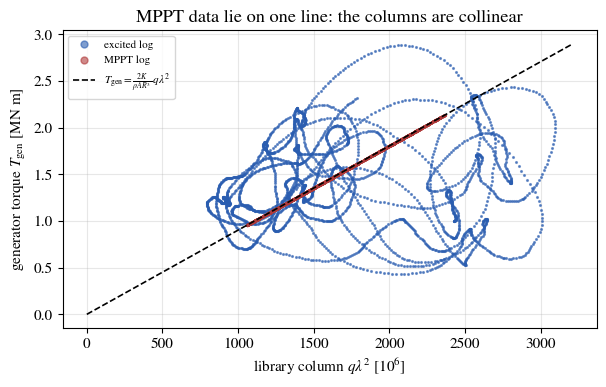

In [4]:
def plot_collinear():
    fig, ax = plt.subplots(figsize=(6.2, 4.0))
    for lab, col, mk in [('excited', 'C0', '.'), ('MPPT', 'C3', '.')]:
        t_, OM_, V_, TG_, _ = logs[lab]; th3 = design(OM_, V_, TG_)[:, 3]
        ax.plot(th3[::4]/1e6, TG_[::4]/1e6, mk, color=col, ms=2.5, alpha=0.6, label=f'{lab} log')
    xx = np.linspace(0, ax.get_xlim()[1], 2)
    ax.plot(xx, 2*K/(rho*A*R**3)*xx, '--', color=fg(), lw=1.2, label='$T_{\\mathrm{gen}}=\\frac{2K}{\\rho AR^3}\\,q\\lambda^2$')
    ax.set(xlabel='library column $q\\lambda^2$ [$10^6$]', ylabel='generator torque $T_{\\mathrm{gen}}$ [MN m]',
           title='MPPT data lie on one line: the columns are collinear')
    ax.legend(fontsize=8, markerscale=4); plt.tight_layout()

save_dual(plot_collinear, 'ed_turbine_collinear', FIG)
plt.show()

Under MPPT the ratio $T_{\mathrm{gen}}/(q\lambda^2)$ is the same constant to every printed digit, the condition
number is at the rounding limit, and least squares returns an arbitrary point on the null line: here an inertia of $8.7\times10^{12}$~kg\,m$^2$,
five orders of magnitude too large, with a meaningless $C_p$ polynomial. With the dithered gain the generator column
leaves the span of the aerodynamic columns, the condition number drops to about $2\times10^4$, the inertia is within
$0.01\%$ and $C_p(\lambda)$ is recovered over the range of tip-speed ratios the data visited. Below that range
the polynomial is an extrapolation and it shows: a correct *structure* (dimensional analysis) is not a correct
*function* where the data never went.

## 3–4. Validation: same wind law, different controllers

Simulate both identified models and the truth on an unseen turbulent wind ($8.5$~m/s mean, another seed), first with
the MPPT law they were identified under and then with the torque gain raised and lowered by $40\%$.

In [5]:
v_te, _, _ = turbine.turbulent_wind(V_TEST, t_end=T_END, dt=DT, TI=TI, tau=TAU_W, seed=SEED_TEST)
def model_rhs(xi):
    def rhs(om, v, tg):
        lam = om*R/v; q = 0.5*rho*A*R*v**2
        return sum(xi[k]*q*lam**(k - 1) for k in range(DEG + 1)) + xi[-1]*tg
    return rhs
val = {}
for g in GAINS:
    tt, Ot, *_ = simulate(v_te, T_END, gain=lambda t, g=g: g)
    for lab in fits:
        Om = simulate(v_te, T_END, gain=lambda t, g=g: g, rhs=model_rhs(fits[lab]))[1]
        val[(g, lab)] = (Om, float(np.linalg.norm(Om - Ot)/np.linalg.norm(Ot)))
    val[(g, 'truth')] = (Ot, 0.0)
print(f'{"gain":>5} | {"MPPT-identified":>16} {"excited":>10}   relative L2 error of omega(t) over {T_END:.0f} s')
for g in GAINS: print(f'{g:5.1f} | {val[(g, "MPPT")][1]:16.1e} {val[(g, "excited")][1]:10.1e}')
if AT_DEFAULTS:
    assert val[(1.0, 'MPPT')][1] < 1e-4 and val[(1.4, 'MPPT')][1] > 0.05 and max(val[(g, 'excited')][1] for g in GAINS) < 1e-3

 gain |  MPPT-identified    excited   relative L2 error of omega(t) over 600 s
  1.0 |          1.5e-06    7.8e-05
  1.4 |          1.4e-01    6.9e-05
  0.6 |          1.4e-01    6.2e-05


The MPPT-identified model reproduces the MPPT turbine on unseen wind to $10^{-6}$: on the manifold
$T_{\mathrm{gen}}=K\omega^2$ its wrong inertia and wrong $C_p$ cancel exactly. Change the gain and the cancellation is
gone; the error jumps to over ten percent. The excited model is right for every controller. The lesson generalizes to
every discovery from operational data: a model identified in closed loop is validated only for that loop. A
digital twin that will be used to *redesign the controller* must be identified from data in which the controller
was perturbed.

## 5. Noise on the rotor speed

Logged $\omega$ with Gaussian noise; derivatives by `np.gradient` (finite differences) or the weak form of the vessel
notebook ($150$ windows of $20$~s, bump $((t-a)(b-t))^4$). Noise also enters the columns through $\lambda=\omega R/v$.

In [6]:
trapz = getattr(np, 'trapezoid', None) or np.trapz
t, OM, V, TG, DOM = logs['excited']
def weak(om, n_w=150, width=400, qd=4):
    Th = design(om, V, TG); st = np.linspace(0, len(t) - width - 1, n_w).astype(int); G, b = [], []
    for s in st:
        tk = t[s:s + width + 1]; a, bb = tk[0], tk[-1]
        phi = ((tk - a)*(bb - tk))**qd; dphi = qd*((tk - a)*(bb - tk))**(qd - 1)*((bb - tk) - (tk - a)); sc = trapz(phi, tk)
        b.append(-trapz(dphi*om[s:s + width + 1], tk)/sc); G.append(trapz(phi[:, None]*Th[s:s + width + 1], tk, axis=0)/sc)
    return np.array(G), np.array(b)
lg6 = np.linspace(6, 12, 25)
def cp_err(xi): return float(np.abs(cp_hat(xi, lg6) - p.Cp(lg6, 0.0)).max())
noise_rows = []
for lev in NOISES:
    rng = np.random.default_rng(0); om_n = OM + lev*OM.std()*rng.standard_normal(len(OM))
    xi_fd = np.linalg.lstsq(design(om_n, V, TG), np.gradient(om_n, t), rcond=None)[0]
    G, b = weak(om_n); xi_w = np.linalg.lstsq(G, b, rcond=None)[0]
    noise_rows.append((lev, -1/xi_fd[-1], cp_err(xi_fd), -1/xi_w[-1], cp_err(xi_w)))
print(f'{"noise":>6} | {"J, FD":>8} {"C_p err":>8} | {"J, weak":>8} {"C_p err":>8}   (J in 1e6 kg m^2, true {J/1e6:.1f}; C_p max error on lambda in [6, 12])')
for lev, jf, cf, jw, cw in noise_rows:
    print(f'{lev*100:5.1f}% | {jf/1e6:8.2f} {cf:8.3f} | {jw/1e6:8.2f} {cw:8.3f}')

 noise |    J, FD  C_p err |  J, weak  C_p err   (J in 1e6 kg m^2, true 38.6; C_p max error on lambda in [6, 12])
  0.0% |    38.62    0.003 |    38.58    0.003
  0.1% |    38.61    0.004 |    38.58    0.003
  0.5% |    38.59    0.008 |    38.58    0.003
  1.0% |    38.56    0.013 |    38.59    0.002


The drivetrain is a slow, heavily filtered system ($J$ is huge), so even finite differences keep the inertia within
a tenth of a percent at $1\%$ noise; the coefficient map is what degrades, by a factor of four, and the weak form
holds it. Measurement noise is not the hard part of this problem. Excitation is.

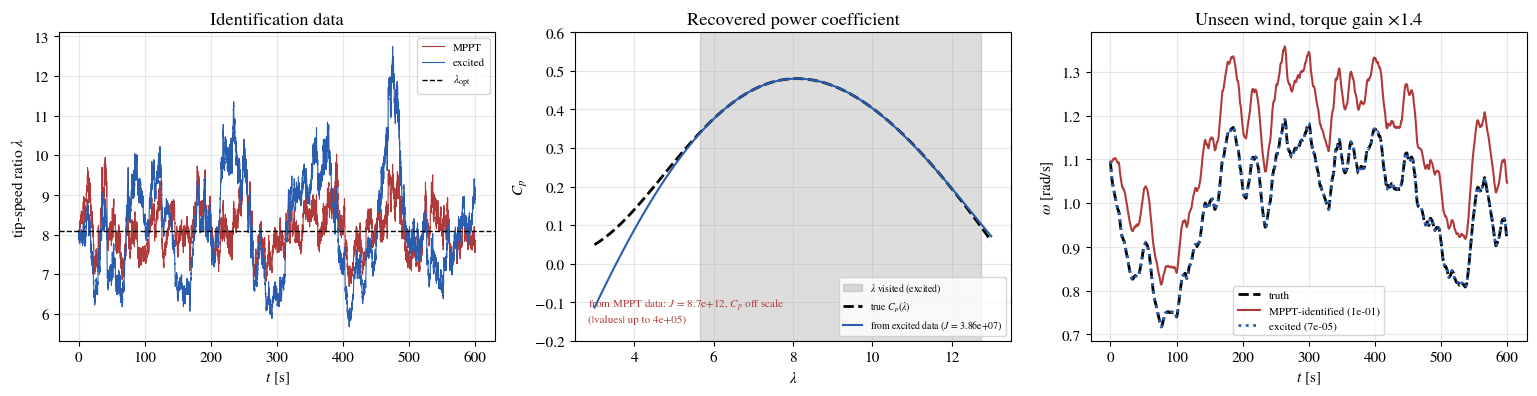

In [7]:
def plot_turbine():
    fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.1))
    for lab, col in [('MPPT', 'C3'), ('excited', 'C0')]:
        t_, OM_, V_, *_ = logs[lab]; ax[0].plot(t_, OM_*R/V_, color=col, lw=0.8, label=lab)
    ax[0].axhline(p.lam_opt, color=fg(), ls='--', lw=1, label='$\\lambda_{\\mathrm{opt}}$')
    ax[0].set(xlabel='$t$ [s]', ylabel='tip-speed ratio $\\lambda$', title='Identification data'); ax[0].legend(fontsize=8)
    ax[1].axvspan(lam_x.min(), lam_x.max(), color=muted(), alpha=0.2, label='$\\lambda$ visited (excited)')
    ax[1].plot(lg, p.Cp(lg, 0.0), '--', color=fg(), lw=2, label='true $C_p(\\lambda)$')
    ax[1].plot(lg, cp_hat(fits['excited'], lg), color='C0', label=f'from excited data ($J$ = {J_exc:.3g})')
    ax[1].text(0.03, 0.06, f'from MPPT data: $J$ = {J_mppt:.1e}, $C_p$ off scale\n(|values| up to {np.abs(cp_hat(fits["MPPT"], lg)).max():.0e})',
               transform=ax[1].transAxes, color='C3', fontsize=8)
    ax[1].set(xlabel='$\\lambda$', ylabel='$C_p$', ylim=(-0.2, 0.6), title='Recovered power coefficient'); ax[1].legend(fontsize=7)
    g = GAINS[1]; tt = np.arange(len(val[(g, 'truth')][0]))*DT
    ax[2].plot(tt, val[(g, 'truth')][0], '--', color=fg(), lw=2, label='truth')
    ax[2].plot(tt, val[(g, 'MPPT')][0], color='C3', label=f'MPPT-identified ({val[(g, "MPPT")][1]:.0e})')
    ax[2].plot(tt, val[(g, 'excited')][0], ':', color='C0', lw=2, label=f'excited ({val[(g, "excited")][1]:.0e})')
    ax[2].set(xlabel='$t$ [s]', ylabel='$\\omega$ [rad/s]', title=f'Unseen wind, torque gain $\\times{g}$'); ax[2].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_turbine, 'ed_turbine', FIG)
plt.show()

**Takeaways.** Dimensional analysis turns an unknown aerodynamic map into a SINDYc library in which the wind
speed is a parameter, and from excited data that library returns the drivetrain inertia exactly and the power
coefficient wherever the data went. From data logged under the turbine's own maximum-power controller it cannot:
$T_{\mathrm{gen}}=K\omega^2$ lies in the span of the library, the regression is rank-deficient, and the identified model
is right only for the controller it was identified under. Data richness, the second assumption of SINDy, is not a
property of the plant alone but of the plant *and* its controller.